In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\malsh\Downloads\archive (5)\diabetes.csv")
print(df.shape)
df.info()
print(df.isna().sum())
print(df.duplicated().sum())
df.describe()

(768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                  

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((df[cols] == 0).sum())
print(((df[cols] == 0).mean() * 100).round(1))
print(df["Outcome"].value_counts())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Glucose           0.7
BloodPressure     4.6
SkinThickness    29.6
Insulin          48.7
BMI               1.4
dtype: float64
Outcome
0    500
1    268
Name: count, dtype: int64


## Task 2: أول نظرة
- الحجم: 768 صف × 9 أعمدة
- لا يوجد نقص ظاهر ولا تكرار
- لكن min = 0 في Glucose وBloodPressure وSkinThickness، وهذا مستحيل طبيًا، فهو نقص مخفي

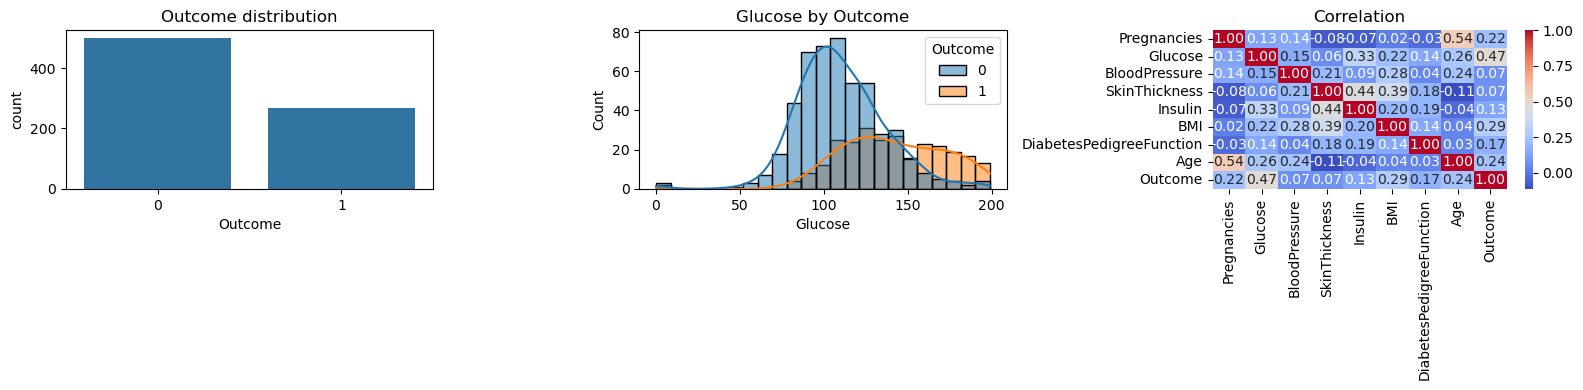

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x="Outcome", data=df, ax=axes[0])
axes[0].set_title("Outcome distribution")

sns.histplot(data=df, x="Glucose", hue="Outcome", kde=True, ax=axes[1])
axes[1].set_title("Glucose by Outcome")

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[2])
axes[2].set_title("Correlation")

plt.tight_layout()
plt.show()

## Task 3: EDA

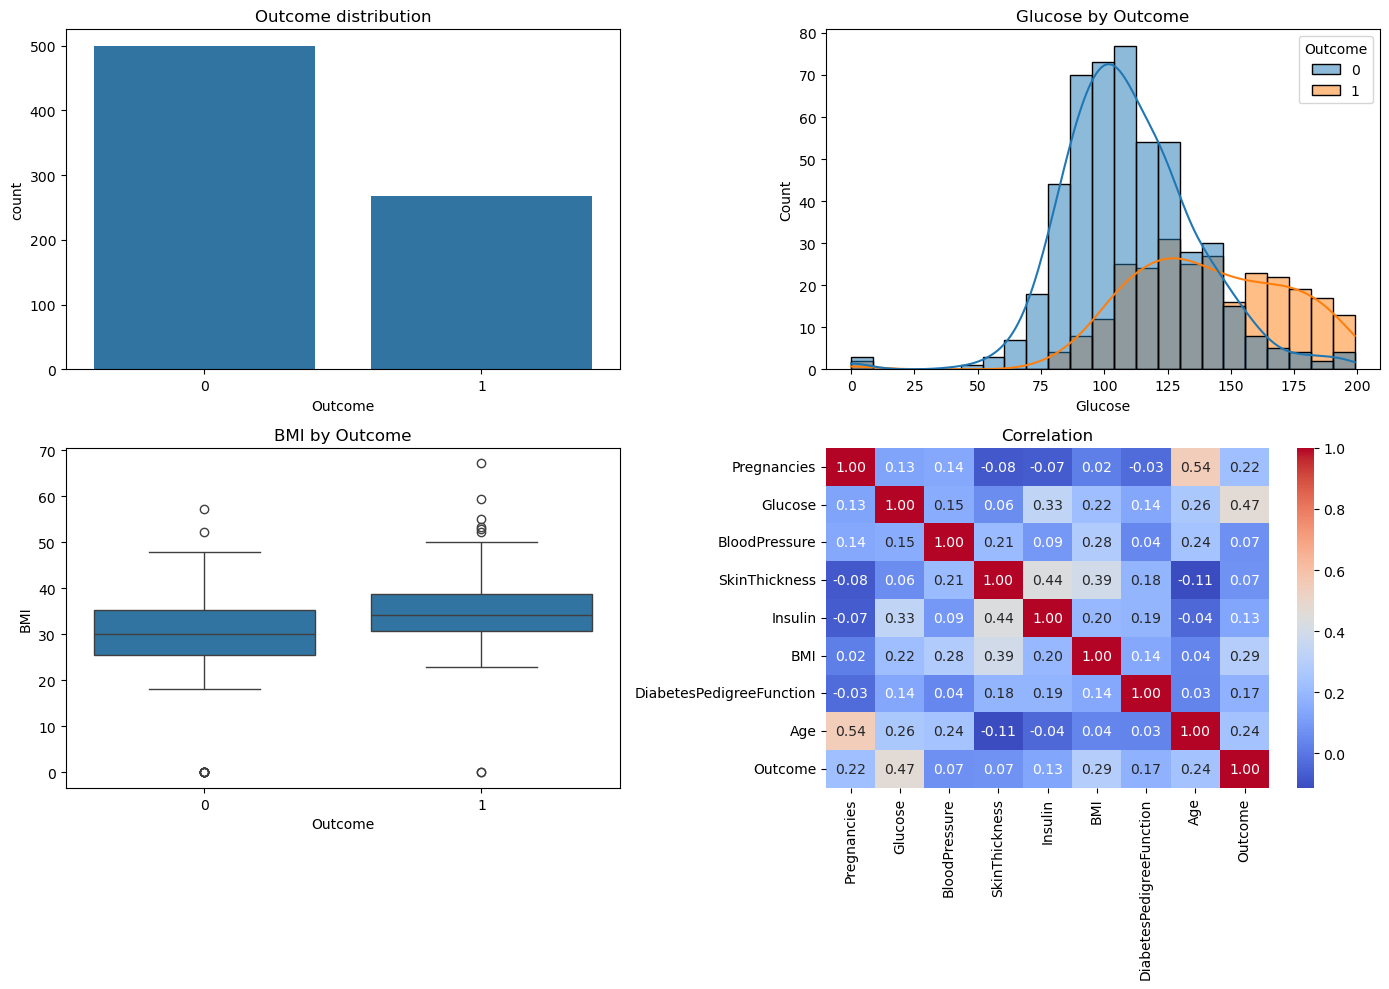

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(x="Outcome", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Outcome distribution")

sns.histplot(data=df, x="Glucose", hue="Outcome", kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Glucose by Outcome")

sns.boxplot(x="Outcome", y="BMI", data=df, ax=axes[1, 0])
axes[1, 0].set_title("BMI by Outcome")

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation")

plt.tight_layout()
plt.show()

## Task 4 Cleaning + Decision Log

In [ ]:
df_clean = df.copy()
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# علم الصفوف الناقصة للعمودين الكثيرين الأصفار
for c in ["SkinThickness", "Insulin"]:
    df_clean[c + "_missing"] = (df_clean[c] == 0).astype(int)

# الصفر يصير NaN
df_clean[cols] = df_clean[cols].replace(0, np.nan)

# حذف صفوف Glucose وBMI الناقصة
before = len(df_clean)
df_clean = df_clean.dropna(subset=["Glucose", "BMI"])
print("Rows dropped:", before - len(df_clean))

# تعويض الباقي بالوسيط
for c in ["BloodPressure", "SkinThickness", "Insulin"]:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

print(df_clean.isna().sum().sum(), df_clean.shape)

Rows dropped: 16
0 (752, 11)


### Decision Log
1. Glucose وBMI: حذفت 16 صف (5 و11)، لأن النسبة أقل من 2% ولا تؤثر على الداتا.
2. BloodPressure: عوضت 35 صف (4.6%) بالوسيط.
3. SkinThickness وInsulin: عوضت 227 و374 صف بالوسيط، وأضفت عمود علم لكل واحد، لأن الحذف يخسرنا نصف الداتا تقريبًا.

## Task 5: Feature Engineering

BMI_category
Underweight    0.00
Normal         0.07
Overweight     0.25
Obese          0.46
Name: Outcome, dtype: float64 

Age_group
Young     0.22
Middle    0.51
Senior    0.49
Name: Outcome, dtype: float64 

Glucose_level
Normal         0.07
Prediabetes    0.28
Diabetes       0.59
Name: Outcome, dtype: float64 



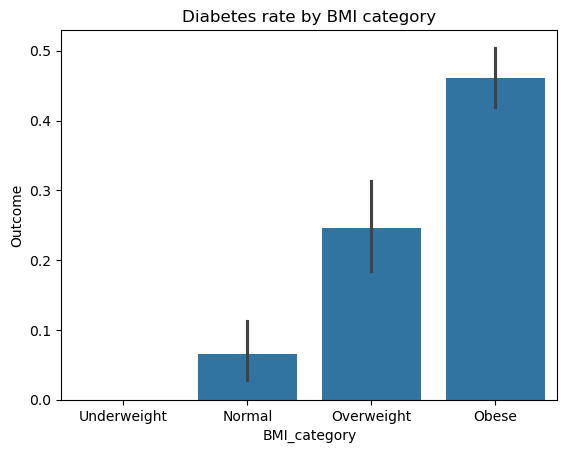

In [ ]:
df_fe = df_clean.copy()

# فئات BMI (تصنيف منظمة الصحة العالمية)
df_fe["BMI_category"] = pd.cut(
    df_fe["BMI"],
    bins=[0, 18.5, 25, 30, 100],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)

# فئات العمر
df_fe["Age_group"] = pd.cut(
    df_fe["Age"],
    bins=[0, 30, 45, 100],
    labels=["Young", "Middle", "Senior"]
)

# فئات Glucose
df_fe["Glucose_level"] = pd.cut(
    df_fe["Glucose"],
    bins=[0, 99, 125, 300],
    labels=["Normal", "Prediabetes", "Diabetes"]
)

# نسبة المصابات في كل فئة
for c in ["BMI_category", "Age_group", "Glucose_level"]:
    print(df_fe.groupby(c, observed=True)["Outcome"].mean().round(2), "\n")

sns.barplot(x="BMI_category", y="Outcome", data=df_fe)
plt.title("Diabetes rate by BMI category")
plt.show()

نسبة الإصابة ترتفع مع BMI: من 7% عند الوزن الطبيعي إلى 46% عند السمنة. فئات Glucose تعطي أقوى فصل (7% إلى 59%)، وفئة العمر فوق 30 تضاعف النسبة تقريبًا. هذي الفئات مبنية على معايير طبية معروفة، وتساعد العيادة تحدد من تفحصه مبكرًا.

## Task 6: Feature Selection

In [ ]:
# ارتباط كل عمود رقمي مع Outcome
corr = df_fe.select_dtypes("number").corr()["Outcome"].drop("Outcome")
print(corr.abs().sort_values(ascending=False).round(2))

# تجهيز الداتا للموديل: نحول الفئات إلى أعمدة 0/1
df_model = pd.get_dummies(
    df_fe, columns=["BMI_category", "Age_group", "Glucose_level"], drop_first=True
)
print(df_model.shape)

df_model.to_csv("diabetes_model_ready.csv", index=False)

Glucose                     0.49
BMI                         0.31
Age                         0.23
Pregnancies                 0.21
SkinThickness               0.21
Insulin                     0.20
DiabetesPedigreeFunction    0.18
BloodPressure               0.16
SkinThickness_missing       0.06
Insulin_missing             0.04
Name: Outcome, dtype: float64
(752, 18)


### Feature Selection

| الميزة | القرار | الدليل |
|---|---|---|
| Glucose | أبقي | أقوى ارتباط (0.49) |
| BMI | أبقي | ارتباط 0.31، والنسبة ترتفع من 7% إلى 46% مع السمنة |
| Age | أبقي | ارتباط 0.23، والنسبة تتضاعف بعد 30 سنة |
| Pregnancies | أبقي | ارتباط 0.21 |
| SkinThickness | أبقي | ارتباط 0.21 (القيم المعوّضة بالوسيط) |
| Insulin | أبقي | ارتباط 0.20 (القيم المعوّضة بالوسيط) |
| DiabetesPedigreeFunction | أبقي | ارتباط 0.18، يمثل العامل الوراثي |
| BloodPressure | أبقي (ضعيف) | ارتباط 0.16 فقط، لكن له معنى طبي |
| SkinThickness_missing | احذف | ارتباط 0.06 |
| Insulin_missing | احذف | ارتباط 0.04 |
| BMI_category / Age_group / Glucose_level | أبقي | نفس معلومات الأعمدة الأصلية بشكل فئات، وتفيد بعض الموديلات |

In [ ]:
df_model = df_model.drop(columns=["SkinThickness_missing", "Insulin_missing"])
print(df_model.shape)
df_model.to_csv("diabetes_model_ready.csv", index=False)

(752, 16)


## Task 7: Results and Recommendations

**ماذا اكتشفت؟**
- Glucose أقوى عامل مرتبط بالسكري (ارتباط 0.49)، يليه BMI (0.31) ثم العمر (0.23).
- الداتا فيها نقص مخفي كبير: 48.7% من Insulin و29.6% من SkinThickness أصفار.

**لمن أوصي بماذا؟**
- للعيادة: ركّزوا الفحص المبكر على النساء فوق 30 سنة، ومن BMI فوق 30، ومن Glucose فوق 99.
- لفريق الداتا: اجمعوا قياسات Insulin وSkinThickness بدقة أكبر قبل بناء أي موديل.

**حدود التحليل:**
- الداتا لنساء فقط، فلا نعمّم على الرجال.
- الارتباط لا يعني السبب.

## ملخص لطبيب العيادة

1. حللت بيانات 768 امرأة لمعرفة العوامل المرتبطة بالسكري، وحوالي 35% منهن مصابات.
2. العامل الأول: مستوى Glucose. نسبة الإصابة 7% عند المستوى الطبيعي، وترتفع إلى 59% عند مستوى السكري.
3. العامل الثاني: كتلة الجسم (BMI). النسبة 7% عند الوزن الطبيعي و46% عند السمنة.
4. العامل الثالث: العمر. النسبة 22% تحت سن 30 وحوالي 50% بعده.
5. أكبر مشكلة في الداتا: قيم مستحيلة طبيًا (صفر) في Insulin بنسبة 49% وSkinThickness بنسبة 30%.
6. عوّضتها بالوسيط وحذفت 16 صفًا فقط عند Glucose وBMI لأن الخطأ فيها نادر.
7. توصيتي: ركّزوا الفحص المبكر على النساء فوق 30 سنة، ومن BMI لديهن فوق 30، ومن Glucose عندهن فوق 99.
8. الأرقام تُظهر ارتباطًا قويًا، لكنها لا تُثبت أن عاملًا واحدًا يسبب المرض.
9. الداتا لنساء من مجموعة واحدة، فقد تختلف النتائج على مرضى عيادتكم.
10. أنصح بتسجيل Insulin وسُمك الجلد بدقة في المرحلة القادمة.